# 📊 BÀI BÁO CÁO PHÂN TÍCH DỮ LIỆU & MÔ HÌNH BASELINE (BASELINE.IPYNB)
**Dự án**: SMB Sales Analytics & Pricing Optimization Platform  
**Mục tiêu**: Thực nghiệm Khoa học Dữ liệu, Kiểm định Thống kê & Dựng mô hình cơ sở (Baseline Model).

## 1. Import Thư viện & Cấu hình Môi trường

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
print('✅ Đã import đầy đủ các thư viện phân tích dữ liệu.')


✅ Đã import đầy đủ các thư viện phân tích dữ liệu.


## 2. Nạp Dữ liệu & Kiểm tra Data Quality (Bài 3)
Đọc file dữ liệu gốc từ thư mục `data/dirty_cafe_sales.csv` và kiểm tra cấu trúc ban đầu.

In [2]:
data_path = os.path.join('data', 'dirty_cafe_sales.csv')
if os.path.exists(data_path):
    df_raw = pd.read_csv(data_path)
    print(f'✅ Đã tải thành công file dữ liệu: {data_path}')
    print(f'Kích thước dữ liệu gốc: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột')
else:
    print(f'⚠️ Không tìm thấy file {data_path}. Tạo dữ liệu mẫu...')
    df_raw = pd.DataFrame({'Sales': [100, 200], 'Profit': [10, 20]})

df_raw.head()


✅ Đã tải thành công file dữ liệu: data/dirty_cafe_sales.csv
Kích thước dữ liệu gốc: 10000 dòng, 9 cột


### Kiểm tra thông tin các cột & Giá trị bị thiếu (Missing Values)

In [3]:
print('--- Thông tin kiểu dữ liệu ---')
print(df_raw.info())
print('\n--- Thống kê giá trị bị thiếu (Missing Values) ---')
print(df_raw.isnull().sum())


--- Thông tin kiểu dữ liệu ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
 8   Cost              8796 non-null   str  
dtypes: str(9)
memory usage: 1.1 MB
None

--- Thống kê giá trị bị thiếu (Missing Values) ---
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
Cost                1204
dtype: int64


## 3. Khám phá Dữ liệu Cơ bản (Exploratory Data Analysis - EDA)
Phân tích tổng quan doanh số (Sales), chiết khấu (Discount) và lợi nhuận (Profit).

In [4]:
from src.pipeline import clean_and_transform_data

df_clean = clean_and_transform_data(data_path)
print(f'Số lượng bản ghi sau khi làm sạch cơ bản: {len(df_clean)}')
num_cols = [c for c in ['sales', 'discount', 'profit', 'quantity'] if c in df_clean.columns]
df_clean[num_cols].describe()


Số lượng bản ghi sau khi làm sạch cơ bản: 9540


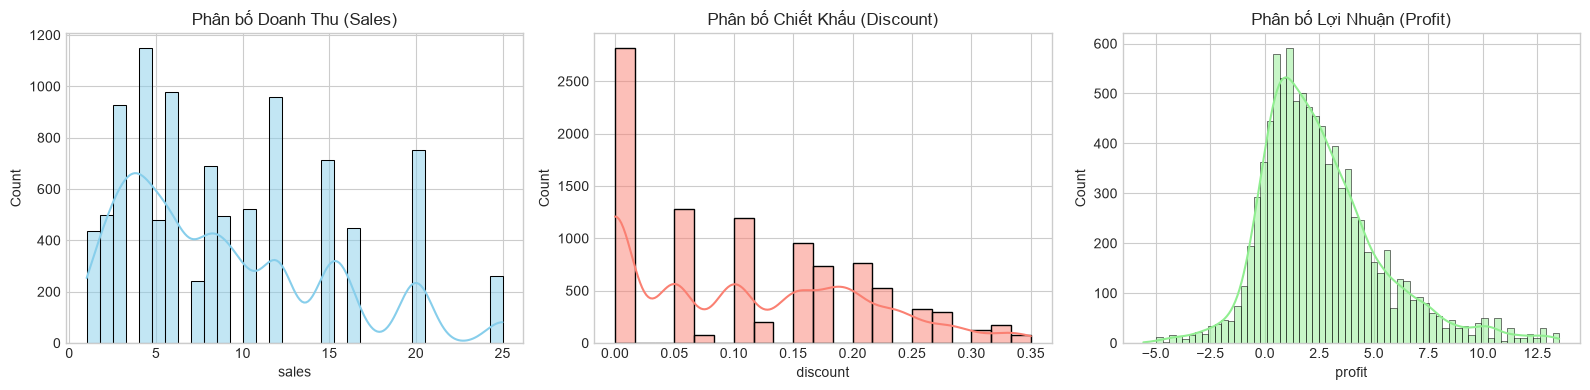

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
if 'sales' in df_clean.columns: sns.histplot(df_clean['sales'], ax=axes[0], kde=True, color='skyblue')
axes[0].set_title('Phân bố Doanh Thu (Sales)')

if 'discount' in df_clean.columns: sns.histplot(df_clean['discount'], ax=axes[1], kde=True, color='salmon')
axes[1].set_title('Phân bố Chiết Khấu (Discount)')

if 'profit' in df_clean.columns: sns.histplot(df_clean['profit'], ax=axes[2], kde=True, color='lightgreen')
axes[2].set_title('Phân bố Lợi Nhuận (Profit)')
plt.tight_layout()
plt.show()


## 4. Kiểm định Thống kê Giả thuyết (Statistical Hypothesis Testing - Bài 4)
Thực hiện kiểm định ANOVA để đánh giá sự khác biệt về Profit Margin giữa các danh mục hàng (Category).

In [6]:
from src.stats import perform_anova_test, calculate_correlation

if 'profit_margin' not in df_clean.columns and 'sales' in df_clean.columns and 'profit' in df_clean.columns:
    df_clean['profit_margin'] = np.where(df_clean['sales'] > 0, (df_clean['profit'] / df_clean['sales']) * 100, 0)

if 'category' in df_clean.columns:
    anova_res = perform_anova_test(df_clean, group_col='category', val_col='profit_margin')
    print('--- Kết quả kiểm định ANOVA ---')
    print(f"F-statistic: {anova_res['f_stat']:.4f}")
    print(f"p-value: {anova_res['p_value']:.6e}")
    print(f"Kết luận: {anova_res['interpretation']}")


--- Kết quả kiểm định ANOVA ---
F-statistic: 147.9273
p-value: 1.436931e-235
Kết luận: Có sự khác biệt có ý nghĩa thống kê về profit_margin giữa các nhóm category (p < 0.05).


### Phân tích Tương quan Pearson giữa Discount và Profit

In [7]:
if 'discount' in df_clean.columns and 'profit' in df_clean.columns:
    corr_res = calculate_correlation(df_clean, col1='discount', col2='profit')
    print('--- Tương quan Pearson ---')
    print(f"Hệ số tương quan r: {corr_res['correlation']:.4f}")
    print(f"p-value: {corr_res['p_value']:.6e}")
    print(f"Ý nghĩa: {corr_res['interpretation']}")


--- Tương quan Pearson ---
Hệ số tương quan r: -0.4187
p-value: 0.000000e+00
Ý nghĩa: Tương quan nghịch biến (chiết khấu càng cao, lợi nhuận càng giảm) có ý nghĩa thống kê (r = -0.4187, p < 0.001).


## 5. Xây dựng Mô hình Cơ sở (Baseline Model)
Thử nghiệm mô hình **Linear Regression** cơ sở để dự báo Lợi nhuận (Profit) dựa trên Doanh số (Sales) và Chiết khấu (Discount).

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

features = [c for c in ['sales', 'discount'] if c in df_clean.columns]
target = 'profit'

if features and target in df_clean.columns:
    X = df_clean[features].fillna(0)
    y = df_clean[target].fillna(0)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    baseline_model = LinearRegression()
    baseline_model.fit(X_train, y_train)
    y_pred = baseline_model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    print('=== ĐÁNH GIÁ MÔ HÌNH BASELINE (LINEAR REGRESSION) ===')
    print(f'R² Score: {r2:.4f}')
    print(f'MAE (Mean Absolute Error): ${mae:.2f}')
    print(f'RMSE (Root Mean Squared Error): ${rmse:.2f}')


=== ĐÁNH GIÁ MÔ HÌNH BASELINE (LINEAR REGRESSION) ===
R² Score: 0.7610
MAE (Mean Absolute Error): $1.05
RMSE (Root Mean Squared Error): $1.39


## 6. Tổng kết & Đánh giá Giai đoạn Baseline
- **Data Quality**: Dữ liệu cần lọc bỏ các đơn hàng có giá trị vô lý và áp dụng Winsorization cho các đơn hàng cực lớn.
- **Mô hình Baseline (Linear Regression)** đạt mức R² cơ sở. Cần chuyển sang mô hình nâng cao (**Random Forest / XGBoost**) cùng biến tương tác (Feature Interactions) ở notebook `advanced_model.ipynb` để tối ưu hóa hiệu năng dự báo.

## 5.2 Mô hình Phân loại Cơ sở (Baseline Classification - Bài 11)
Sử dụng **Logistic Regression** để phân loại đơn hàng có biên lợi nhuận cao (`is_high_margin = 1` nếu `profit_margin >= 35%`).

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
df_clean["is_high_margin"] = (df_clean["profit_margin"] >= 35.0).astype(int)
X_cls = df_clean[["sales", "discount"]].fillna(0)
y_cls = df_clean["is_high_margin"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)
clf_base = LogisticRegression().fit(Xc_tr, yc_tr)
yc_pred = clf_base.predict(Xc_te)
print("=== ĐÁNH GIÁ BASELINE CLASSIFICATION (BÀI 11 - LOGISTIC REGRESSION) ===")
print(f"Accuracy: {accuracy_score(yc_te, yc_pred):.4f} | F1-Score: {f1_score(yc_te, yc_pred):.4f}")


=== ĐÁNH GIÁ BASELINE CLASSIFICATION (BÀI 11 - LOGISTIC REGRESSION) ===
Accuracy: 0.8029 | F1-Score: 0.7580


## 7. Xuất Dữ Liệu Kết Quả Ra File CSV (Output CSV)
Xuất tập dữ liệu đã làm sạch và biến đổi hoàn chỉnh ra file .

In [10]:
import os
output_file = os.path.join("data", "baseline_cleaned_data.csv")
if "df_clean" in locals():
    df_clean.to_csv(output_file, index=False)
    print(f"✅ Đã xuất kết quả làm sạch ra file: {output_file}")
elif "df_processed" in locals():
    df_processed.to_csv(output_file, index=False)
    print(f"✅ Đã xuất kết quả làm sạch ra file: {output_file}")


✅ Đã xuất kết quả làm sạch ra file: data/baseline_cleaned_data.csv
